# Notebook 2 · Wednesday lab & Thursday: concurrency, SGS-DRS and policy optimization
**MIME 525 · Simulation-Based Optimization and Reinforcement Learning**

This notebook follows the slides **in order**:
* **Wednesday lab:** Exercises 1–4 (concurrency), Exercise 5 (Optuna)
* **Thursday Part 1:** SGS step by step, Exercises 6–7 (parallel SGS), Amdahl's law, one DRS period by hand
* **Thursday Part 2:** Exercise 8 (Bayesian optimization of the cutoff policy), risk-aware objective, Exercise 9 (bandit)

Each section is headed with its slide number. **Before you start:** put `sgs_tools.py` next to this notebook (on Colab, the next cell asks you to upload it).
`sgs_tools.py` holds the functions that run on several CPU cores: Python can only send a function to another core if it lives in a `.py` file.

> Free Colab has 2 *virtual* CPUs sharing one physical core, so parallel speed-ups there are small. A laptop usually shows bigger ones.

In [1]:
# Colab only: install Optuna and upload sgs_tools.py if needed. On a laptop: pip install optuna
import os
import warnings
warnings.filterwarnings("ignore")
try:
    import optuna
except ImportError:
    os.system("pip install -q optuna")
if not os.path.exists("sgs_tools.py"):
    from google.colab import files
    files.upload()

In [2]:
import time
import threading
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, as_completed
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import sgs_tools

print("CPU cores this computer reports:", os.cpu_count())

CPU cores this computer reports: 14


---
## Slide 46 · Exercise 1 · Sequential baseline: two counters, in order
One worker counts truck A's loads, *then* truck B's. Write down the time: it is your **baseline**.

In [3]:
n = 20_000_000

def count(n):
    total = 0
    for _ in range(n):
        total += 1
    return total

t0 = time.perf_counter()
a = count(n)
b = count(n)
print(a + b, time.perf_counter() - t0)

40000000 3.2923240000382066


---
## Slide 47 · Exercise 2 · The lost update problem
Two **threads** add to the **same** total: *read → add one → write*. If the computer switches threads between the read and the write, one increment is lost.
**Predict before you run.**

In [4]:
n = 1_000_000
total = 0

def count(n):
    global total
    for _ in range(n):
        total = (lambda x: x + 1)(total)

threads = [threading.Thread(target=count, args=(n,)) for _ in range(2)]

t0 = time.perf_counter()
for t in threads: t.start()
for t in threads: t.join()
print(total, time.perf_counter() - t0)

1509403 0.6654718000208959


*(Why the `lambda`? Since Python 3.10 a plain `total += 1` almost never shows the problem, even though it is still unsafe. The function call between the read and the write makes the switch happen often.)*

---
## Slide 48 · Exercise 3 · Using locks
A **lock** is the single key to the scale house: only the thread holding it may read, add and write.

In [5]:
n = 1_000_000
total = 0
lock = threading.Lock()

def count(n):
    global total
    for _ in range(n):
        with lock:
            total = (lambda x: x + 1)(total)

threads = [threading.Thread(target=count, args=(n,)) for _ in range(2)]

t0 = time.perf_counter()
for t in threads: t.start()
for t in threads: t.join()
print(total, time.perf_counter() - t0)

2000000 1.1517625999404117


---
## Slide 49 · Exercise 4 · Parallelism with processes
The slide shows the script version (with `if __name__ == "__main__":`). In a notebook we use `sgs_tools.count`, the same `count` function saved in `sgs_tools.py`.
Speed-up = time of Exercise 1 ÷ this time.

In [6]:
n = 20_000_000

t0 = time.perf_counter()
with ProcessPoolExecutor(2) as pool:
    a, b = pool.map(sgs_tools.count, [n, n])
print(a + b, time.perf_counter() - t0)

40000000 2.6091879999730736


---
## Slide 50 · Exercise 5 · Bayesian optimization with Optuna
Monday's SAG mill example: noisy profit ($k/h) vs throughput (t/h); the true best is 1 696 t/h. Optuna proposes each next throughput to try.

Optuna TPE, 11 trials: 1658 t/h
Optuna TPE, 30 trials: 1657 t/h
Random,     11 trials: 1543 t/h


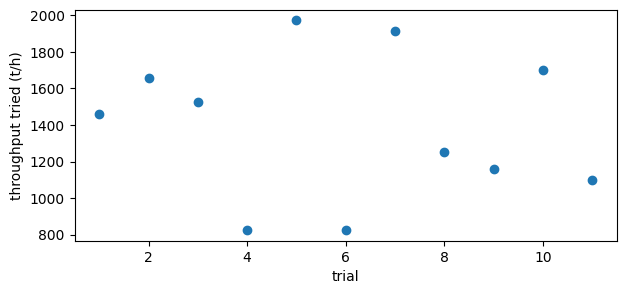

In [7]:
def plant_trial(throughput, rng):
    """Profit in $k/h for one trial (Monday's SAG mill example)."""
    x = (throughput - 800) / 1200
    recovery = 0.93 - 0.35 * x**2 - 0.04 * np.sin(6 * x)
    profit = throughput * (0.006 * 1000 * recovery * 9 - 6) / 1000
    return profit + rng.normal(0, 0.4)

def run_optuna(sampler, n_trials):
    rng = np.random.default_rng(1)
    def objective(trial):
        t = trial.suggest_float("throughput", 800, 2000)
        return plant_trial(t, rng)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials)
    return study

tpe = optuna.samplers.TPESampler(seed=0, n_startup_trials=3)       # 3 random trials, then model-based
study = run_optuna(tpe, 11)
print("Optuna TPE, 11 trials:", round(study.best_params["throughput"]), "t/h")
print("Optuna TPE, 30 trials:", round(run_optuna(optuna.samplers.TPESampler(seed=0, n_startup_trials=3), 30).best_params["throughput"]), "t/h")
print("Random,     11 trials:", round(run_optuna(optuna.samplers.RandomSampler(seed=2), 11).best_params["throughput"]), "t/h")

tried = [t.params["throughput"] for t in study.trials]
plt.figure(figsize=(7, 3))
plt.scatter(range(1, len(tried) + 1), tried)
plt.xlabel("trial")
plt.ylabel("throughput tried (t/h)")
plt.show()

---
## Slide 53 · Normal scores: simulate in Gaussian space, report in % Cu
Our toy model: grades are lognormal with mean 0.45 % Cu, so the transform is a formula.

z = -1  ->  grade 0.21 % Cu
z = +0  ->  grade 0.38 % Cu
z = +1  ->  grade 0.68 % Cu
grade 0.80 % Cu -> z = 1.26


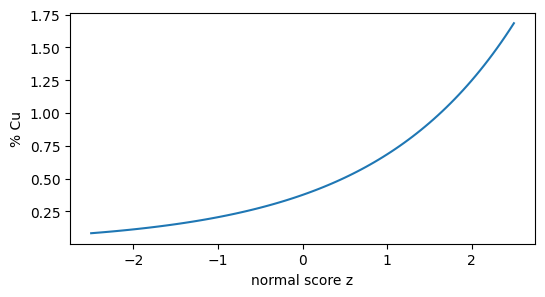

In [8]:
def to_normal_score(grade):
    return (np.log(grade) - np.log(0.45) + 0.18) / 0.6

def to_grade(z):
    return np.exp(np.log(0.45) - 0.18 + 0.6 * z)

for z in [-1, 0, 1]:
    print(f"z = {z:+d}  ->  grade {to_grade(z):.2f} % Cu")
print("grade 0.80 % Cu -> z =", round(to_normal_score(0.80), 2))

z = np.linspace(-2.5, 2.5, 101)
plt.figure(figsize=(6, 3))
plt.plot(z, to_grade(z))
plt.xlabel("normal score z")
plt.ylabel("% Cu")
plt.show()

---
## Slide 54 · One SGS step by hand: krige, draw, back-transform
Block X; neighbours A (2 blocks away, z = +1.2) and B (5 blocks away, z = −0.4); A and B are 4 blocks apart. Covariance C(h) = exp(−3h / 12).

In [9]:
def C(h):
    return np.exp(-3 * h / 12)

K = np.array([[1, C(4)],          # similarity among the data (A-A, A-B / B-A, B-B)
              [C(4), 1]])
k = np.array([C(2), C(5)])         # similarity of each datum to X
w = np.linalg.solve(K, k)          # kriging weights
data = np.array([1.2, -0.4])

mean = w @ data
variance = 1 - w @ k
epsilon = 0.5                      # the random draw (a new seed gives a new value)
z = mean + np.sqrt(variance) * epsilon
print("C(2), C(5), C(4) =", np.round([C(2), C(5), C(4)], 3))
print("weights w_A, w_B =", np.round(w, 3))
print(f"mean {mean:.3f}, variance {variance:.3f}, sd {np.sqrt(variance):.3f}")
print(f"z = {z:.3f}  ->  grade {to_grade(z):.2f} % Cu")

C(2), C(5), C(4) = [0.607 0.287 0.368]
weights w_A, w_B = [0.58  0.073]
mean 0.666, variance 0.627, sd 0.792
z = 1.062  ->  grade 0.71 % Cu


---
## Slide 55 · What one SGS run produces
`sgs_tools.sgs_2d(seed)` repeats the step above for all 1 600 blocks (up to 12 neighbours each). Two realizations, their average (E-type) and the chance each block is ore:

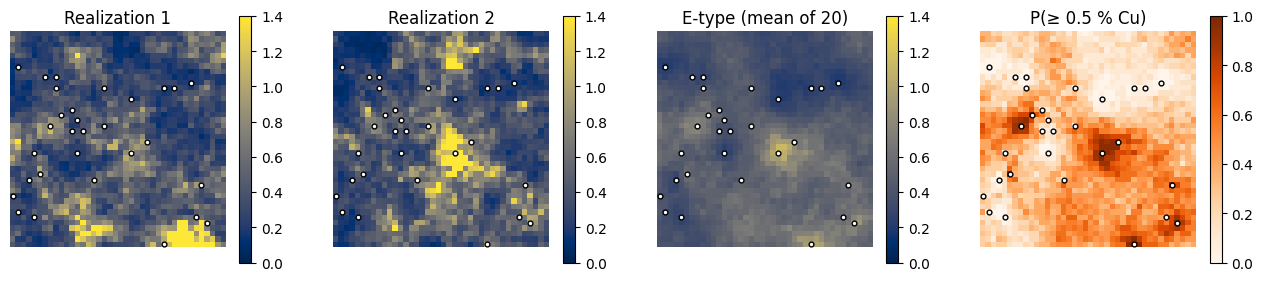

In [10]:
with ProcessPoolExecutor() as pool:
    models = np.array(list(pool.map(sgs_tools.sgs_2d, range(20))))
holes, _ = sgs_tools.drillholes()
hx = [h[0] for h in holes]
hy = [h[1] for h in holes]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
pictures = [models[0], models[1], models.mean(axis=0), (models >= 0.5).mean(axis=0)]
titles = ["Realization 1", "Realization 2", "E-type (mean of 20)", "P(≥ 0.5 % Cu)"]
for i in range(4):
    img = ax[i].imshow(pictures[i].T, origin="lower", cmap="cividis" if i < 3 else "Oranges",
                       vmin=0, vmax=1.4 if i < 3 else 1)
    ax[i].scatter(hx, hy, s=12, c="white", edgecolors="black")
    ax[i].set_title(titles[i])
    ax[i].axis("off")
    plt.colorbar(img, ax=ax[i], shrink=0.8)
plt.show()

---
## Slide 56 · Exercise 6 · SGS realizations in parallel
Inside one realization SGS is **sequential**; across realizations it is **independent** (each needs only its seed). `sgs_tools.sgs_1d` is a line of 20,000 samples along a drillhole:
```python
def sgs_1d(seed, n=20_000, r=0.95):
    rng = np.random.default_rng(seed)          # every realization gets its own seed
    z = [rng.standard_normal()]
    for _ in range(n - 1):                     # SEQUENTIAL: needs the previous value
        z.append(r * z[-1] + (1 - r**2) ** 0.5 * rng.standard_normal())
    grade = np.exp(-0.98 + 0.6 * np.array(z))  # turn normal scores into % Cu
    return np.mean(grade >= 0.5)               # fraction of ore
```

In [11]:
seeds = range(200)
t0 = time.perf_counter()
ore = [sgs_tools.sgs_1d(s) for s in seeds]               # 1 core
print("1-D, 1 core    ", round(time.perf_counter() - t0, 2), "s")
t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:                      # all cores
    ore_p = list(pool.map(sgs_tools.sgs_1d, seeds))
print("1-D, all cores ", round(time.perf_counter() - t0, 2), "s   same result:", ore == ore_p)

seeds = range(32)                                        # the 2-D model
t0 = time.perf_counter()
results = [sgs_tools.ore_summary(s) for s in seeds]
time_1 = time.perf_counter() - t0
t0 = time.perf_counter()
with ProcessPoolExecutor() as pool:
    results = list(pool.map(sgs_tools.ore_summary, seeds))
time_all = time.perf_counter() - t0
print(f"2-D, 1 core {time_1:.2f} s -> all cores {time_all:.2f} s   ({time_1 / time_all:.2f}x faster)")

ore = [r["ore_Mt"] for r in results]
cu = [r["cu_kt"] for r in results]
print("Ore (Mt): P10", round(np.percentile(ore, 10), 2), " P50", round(np.percentile(ore, 50), 2), " P90", round(np.percentile(ore, 90), 2))
print("Cu (kt):  P10", round(np.percentile(cu, 10), 1), " P50", round(np.percentile(cu, 50), 1), " P90", round(np.percentile(cu, 90), 1))

1-D, 1 core     7.32 s
1-D, all cores  3.75 s   same result: True
2-D, 1 core 5.71 s -> all cores 4.35 s   (1.31x faster)
Ore (Mt): P10 11.68  P50 14.15  P90 16.36
Cu (kt):  P10 89.4  P50 114.9  P90 132.3


---
## Slide 57 · Exercise 7 · Use results as they finish, and stop when you know enough
Ask for up to 200 realizations, look at each result **as soon as it finishes**, stop once the average contained Cu is known within ±3 kt (standard error).

In [12]:
cu = []
order = []
with ProcessPoolExecutor() as pool:
    jobs = [pool.submit(sgs_tools.ore_summary, s) for s in range(200)]
    for job in as_completed(jobs):                      # in the order they FINISH
        cu.append(job.result()["cu_kt"])
        order.append(job.result()["seed"])
        error = np.std(cu) / np.sqrt(len(cu))           # uncertainty of the average
        if len(cu) >= 10 and error < 3:
            for j in jobs:
                j.cancel()                              # drop the jobs not started yet
            break
print("Needed", len(cu), "of 200 realizations")
print("Mean contained Cu:", round(np.mean(cu), 1), "±", round(2 * error, 1), "kt (95 %)")
print("Finish order:", order[:10])

Needed 50 of 200 realizations
Mean contained Cu: 109.7 ± 5.9 kt (95 %)
Finish order: [4, 1, 5, 7, 8, 2, 11, 13, 0, 14]


---
## Slide 58 · Amdahl's law
A run of time T has a serial part (1 − p)T and a parallel part pT. With n cores: T(n) = (1 − p)T + pT / n, so the speed-up is **1 / ((1 − p) + p / n)**.

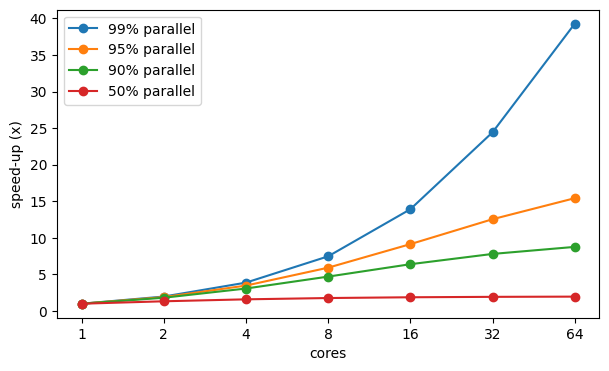

p = 95 %, 16 cores -> 9.1 x


In [13]:
cores = np.array([1, 2, 4, 8, 16, 32, 64])
plt.figure(figsize=(7, 4))
for p in [0.99, 0.95, 0.90, 0.50]:
    plt.plot(range(len(cores)), 1 / ((1 - p) + p / cores), marker="o", label=f"{p:.0%} parallel")
plt.xticks(range(len(cores)), cores)
plt.xlabel("cores")
plt.ylabel("speed-up (x)")
plt.legend()
plt.show()
print("p = 95 %, 16 cores ->", round(1 / (0.05 + 0.95 / 16), 1), "x")

---
## Slide 60 · One DRS period by hand
The first period of realization 0 with the policy cutoff 0.42 % / stockpile cutoff 0.32 %, written out step by step (the same logic as `sgs_tools.mine_npv`).

In [14]:
grade = sgs_tools.sgs_2d(0)
cutoff, stockpile_cutoff = 0.42, 0.32
mined = list(grade.ravel()[:8])                                   # first 8 blocks in mining order
rng = np.random.default_rng(0)
availability = np.clip(rng.normal(1.0, 0.15), 0.4, 1.2)
room = round(sgs_tools.PLANT_SIZE * availability)

to_plant = [g for g in mined if g >= cutoff]
stockpile = sorted(g for g in mined if stockpile_cutoff <= g < cutoff)
from_stockpile = []
while len(to_plant) + len(from_stockpile) < room and stockpile:
    from_stockpile.append(stockpile.pop())                        # best stockpiled block first

print("grades:", [round(g, 3) for g in mined])
print(f"availability {availability:.2f} -> room for {room} blocks")
print("to plant:", [round(g, 3) for g in to_plant], " reclaimed:", [round(g, 3) for g in from_stockpile])

t = sgs_tools.BLOCK_TONNES
cu_fresh = sum(to_plant) / 100 * t * sgs_tools.RECOVERY
cu_stock = sum(from_stockpile) / 100 * t * sgs_tools.STOCKPILE_RECOVERY
revenue = (cu_fresh + cu_stock) * sgs_tools.PRICE
processing = (len(to_plant) + len(from_stockpile)) * t * sgs_tools.PLANT_COST
rehandling = len(from_stockpile) * t * sgs_tools.REHANDLE_COST
mining = len(mined) * t * sgs_tools.MINING_COST
cash = revenue - processing - rehandling - mining - sgs_tools.FIXED_COST
print(f"Cu: fresh {cu_fresh:.1f} t + stockpile {cu_stock:.1f} t = {cu_fresh + cu_stock:.1f} t")
for name, value in [("revenue", revenue), ("processing", -processing), ("rehandling", -rehandling),
                    ("mining", -mining), ("fixed", -sgs_tools.FIXED_COST), ("cash", cash)]:
    print(f"  {name:10s} {value / 1e6:+.3f} $M")
print("NPV of the whole mine life on this realization:", round(sgs_tools.mine_npv(grade, cutoff, stockpile_cutoff, seed=0), 1), "$M")

grades: [np.float64(0.439), np.float64(0.58), np.float64(0.423), np.float64(0.352), np.float64(0.251), np.float64(0.27), np.float64(0.287), np.float64(0.359)]
availability 1.02 -> room for 4 blocks
to plant: [np.float64(0.439), np.float64(0.58), np.float64(0.423)]  reclaimed: [np.float64(0.359)]
Cu: fresh 317.1 t + stockpile 71.8 t = 388.9 t
  revenue    +3.694 $M
  processing -1.200 $M
  rehandling -0.037 $M
  mining     -0.500 $M
  fixed      -1.000 $M
  cash       +0.957 $M
NPV of the whole mine life on this realization: 441.8 $M


---
## Slide 62 · Exercise 8 · Optimizing the cutoff policy with Bayesian optimization
1. **SGS**: 50 equally likely grade models, in parallel. 2. **DRS**: `sgs_tools.mine_npv` returns the NPV of one model.
3. **Policy variables**: `cutoff` and `stockpile_cutoff`. 4. **Optimizer**: Optuna. Tune on 30 models, test on 20 unseen ones.

The toy mine: 25 kt blocks, 200 kt mined and 100 kt processed per week (about 5 Mt/y through the plant), Cu at $9 500/t, 8 %/y discount. NPV in $M.

In [15]:
with ProcessPoolExecutor() as pool:
    models = list(pool.map(sgs_tools.sgs_2d, range(50)))
train, test = models[:30], models[30:]

def npvs(models, cutoff, stockpile_cutoff, first_seed=0):
    return np.array([sgs_tools.mine_npv(g, cutoff, stockpile_cutoff, seed=first_seed + i) for i, g in enumerate(models)])

def objective(trial):
    cutoff = trial.suggest_float("cutoff", 0.3, 1.0)
    stockpile_cutoff = trial.suggest_float("stockpile_cutoff", 0.2, 0.6)
    return npvs(train, cutoff, stockpile_cutoff).mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=25)
best = study.best_params
print("Best policy:", {k: round(v, 2) for k, v in best.items()}, " mean NPV on training models:", round(study.best_value, 1), "$M")

def test_report(name, cutoff, stockpile_cutoff):
    v = npvs(test, cutoff, stockpile_cutoff, first_seed=500)
    print(f"{name:10s} test mean NPV {v.mean():5.1f} $M   P10 {np.percentile(v, 10):6.1f} $M")

test_report("Baseline", 0.5, 0.5)
test_report("Optimized", best["cutoff"], best["stockpile_cutoff"])

Best policy: {'cutoff': 0.35, 'stockpile_cutoff': 0.28}  mean NPV on training models: 502.9 $M
Baseline   test mean NPV 332.8 $M   P10  229.9 $M
Optimized  test mean NPV 473.8 $M   P10  385.6 $M


---
## Slide 63 · Worked example: optimize the average, or the bad case?
Same search, but the objective is the **P10** of NPV (the value 90 % of realizations beat) instead of the mean.

In [16]:
def objective_p10(trial):
    cutoff = trial.suggest_float("cutoff", 0.3, 1.0)
    stockpile_cutoff = trial.suggest_float("stockpile_cutoff", 0.2, 0.6)
    return np.percentile(npvs(train, cutoff, stockpile_cutoff), 10)

study_p10 = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study_p10.optimize(objective_p10, n_trials=25)
best_p10 = study_p10.best_params

for name, (c, s) in {"Mean NPV": (best["cutoff"], best["stockpile_cutoff"]),
                     "P10 of NPV": (best_p10["cutoff"], best_p10["stockpile_cutoff"]),
                     "Baseline": (0.5, 0.5)}.items():
    tr, te = npvs(train, c, s), npvs(test, c, s, first_seed=500)
    print(f"{name:10s} policy {c:.2f} / {min(s, c):.2f}   train mean {tr.mean():5.1f}  P10 {np.percentile(tr, 10):6.1f}"
          f"   | test mean {te.mean():5.1f}  P10 {np.percentile(te, 10):6.1f}  ($M)")

Mean NPV   policy 0.35 / 0.28   train mean 502.9  P10  397.0   | test mean 473.8  P10  385.6  ($M)
P10 of NPV policy 0.31 / 0.31   train mean 501.1  P10  398.8   | test mean 471.1  P10  383.1  ($M)
Baseline   policy 0.50 / 0.50   train mean 370.9  P10  246.3   | test mean 332.8  P10  229.9  ($M)


---
## Slide 65 · Exercise 9 · Choosing the cutoff with a bandit
Three possible cutoffs (stockpile cutoff 0.30 %) = a bandit with three levers. First the true answer from all 30 training models, then a UCB bandit that does not know it.

In [17]:
cutoffs = [0.35, 0.45, 0.60]
for c in cutoffs:
    v = npvs(train, c, 0.30)
    print(f"cutoff {c:.2f} %: mean NPV {v.mean():5.1f} $M   (std between realizations {v.std():4.1f} $M)")

rng = np.random.default_rng(7)
estimate = np.zeros(3)
tries = np.zeros(3)
for pull in range(300):
    if pull < 3:
        choice = pull
    else:
        choice = int(np.argmax(estimate + 120 * np.sqrt(np.log(pull + 1) / tries)))   # c on the scale of the noise
    model_used = train[rng.integers(30)]                                   # random geology
    npv = sgs_tools.mine_npv(model_used, cutoffs[choice], 0.30, seed=int(rng.integers(1_000_000)))
    tries[choice] += 1
    estimate[choice] += (npv - estimate[choice]) / tries[choice]
print()
for c, n, q in zip(cutoffs, tries, estimate):
    print(f"cutoff {c:.2f} %: pulled {int(n):3d} times, estimated NPV {q:5.1f} $M")

cutoff 0.35 %: mean NPV 504.1 $M   (std between realizations 114.7 $M)
cutoff 0.45 %: mean NPV 498.4 $M   (std between realizations 118.0 $M)
cutoff 0.60 %: mean NPV 481.3 $M   (std between realizations 119.5 $M)

cutoff 0.35 %: pulled 176 times, estimated NPV 508.6 $M
cutoff 0.45 %: pulled  27 times, estimated NPV 467.9 $M
cutoff 0.60 %: pulled  97 times, estimated NPV 496.2 $M
